# FraudInsight XAI
ENSI · Data Mining · II3-IA / II3-IF · 2026-2027

Analyse reproductible des artefacts réellement entraînés. Pour refaire l’entraînement : `python scripts/acquire.py` puis `python scripts/train.py`. L’exécution de ce notebook ne retouche jamais le seuil et ne relance pas implicitement l’apprentissage.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display
results=json.loads((ROOT/'reports/results.json').read_text(encoding='utf-8'))
demo=pd.read_parquet(ROOT/'data/demo/transactions.parquet')

## 1. Problème métier
Classer des transactions pour une capacité hypothétique de revue humaine ; une anomalie n’est pas une preuve de fraude.

In [2]:
print('Modèle retenu en validation :',results['winner'])

Modèle retenu en validation : boosting


## 2. Données et provenance
Kartik Shenoy, Sparkov, Kaggle version 1. Données synthétiques sous CC0. Source : https://www.kaggle.com/datasets/kartik2112/fraud-detection . Montants USD. Aucun nom ni identifiant brut dans cet extrait.

In [3]:
print(results['source'], results['mode'], results['rows'])
print('Période :',results['splits']['train']['start'],results['splits']['test']['end'])
display(demo[['amt','category','is_fraud']].describe(include='all'))

https://www.kaggle.com/datasets/kartik2112/fraud-detection complet 1852394
Période : 2019-01-01 00:00:18+00:00 2020-12-31 23:59:34+00:00


,amt,category,is_fraud
count,5000.000000,5000,5000.000000
unique,NaN,14,NaN
top,NaN,gas_transport,NaN
freq,NaN,505,NaN
mean,67.866962,NaN,0.005400
std,133.487770,NaN,0.073293
min,1.010000,NaN,0.000000
25%,9.807500,NaN,0.000000
50%,46.880000,NaN,0.000000
75%,84.477500,NaN,0.000000


## 3. Déséquilibre
La prévalence naturelle est conservée en validation et test. Pondération comparée au témoin sans pondération seulement sur train.

In [4]:
print('Fraudes :',results['frauds'],'; prévalence :',results['prevalence'])
for name,selection in results['selection'].items():
    display(pd.DataFrame([{'modèle':name,'pondération':c['balanced'],'AP validation':c['validation']['average_precision'],'coût validation':c['validation']['cost']} for c in selection['candidates']]))

Fraudes : 9651 ; prévalence : 0.005210014716091717


,modèle,pondération,AP validation,coût validation
0,logistic,False,0.368049,274124.19
1,logistic,True,0.207497,190855.96


,modèle,pondération,AP validation,coût validation
0,boosting,False,0.871609,69399.29
1,boosting,True,0.876744,31405.93


,modèle,pondération,AP validation,coût validation
0,isolation,False,0.082843,780922.17


,modèle,pondération,AP validation,coût validation
0,lof,False,0.068869,811810.84


## 4. Séparation chronologique
60/20/20 approchés à l’événement ; tous les ex aequo restent ensemble. Les deux CSV source sont réunis puis découpés à nouveau selon le cahier des charges.

In [5]:
display(pd.DataFrame(results['splits']).T)
assert results['splits']['train']['end']<results['splits']['validation']['start']
assert results['splits']['validation']['end']<results['splits']['test']['start']

,rows,fraction,frauds,prevalence,start,end
train,1111436,0.6,6401,0.005759,2019-01-01 00:00:18+00:00,2020-04-07 07:00:14+00:00
validation,370479,0.2,1901,0.005131,2020-04-07 07:00:36+00:00,2020-08-25 01:31:21+00:00
test,370479,0.2,1349,0.003641,2020-08-25 01:31:59+00:00,2020-12-31 23:59:34+00:00


## 5. Variables sans fuite
Fenêtres [t-1h,t[, [t-24h,t[, [t-30j,t[. Aucun label dans les agrégations ; ex aequo exclus. Carte nouvelle et moyenne nulle traitées explicitement. Prétraitement ajusté sur train uniquement.

In [6]:
from src.features import FEATURES,build_features
from src.data import validate
edge=validate(pd.DataFrame({'trans_date_trans_time':['2020-01-01 00:00','2020-01-01 00:00','2020-01-01 01:00'],'cc_num':['a']*3,'amt':[10,30,40],'category':['x']*3,'is_fraud':[0,1,0]}))
f=build_features(edge)
assert f.count_1h.tolist()==[0,0,2]
display(f)

,amt,hour_sin,hour_cos,day_of_week,distance_km,count_1h,count_24h,amount_ratio_30d,seconds_since_previous,history_missing,category
0,10.0,0.000000,1.000000,2.0,NaN,0.0,0.0,NaN,NaN,1.0,x
1,30.0,0.000000,1.000000,2.0,NaN,0.0,0.0,NaN,NaN,1.0,x
2,40.0,0.258819,0.965926,2.0,NaN,2.0,2.0,2.0,3600.0,0.0,x


## 6. Modèles supervisés et anomalies
Logistique pondérée et boosting histogramme, comparés à des témoins non pondérés. Isolation Forest et LOF novelty ne reçoivent pas les étiquettes. Contamination auto ; seuil métier distinct. Budgets de calcul déclarés.

In [7]:
for name,s in results['selection'].items():
    print(name, s['selected']['training_rows'], 'observations entraînement,',round(s['selected']['training_seconds'],2),'secondes')
    display(s['selected']['parameters'])

logistic 1111436 observations entraînement, 6.22 secondes


{'C': 1.0,
 'class_weight': 'balanced',
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': 0.0,
 'max_iter': 400,
 'n_jobs': None,
 'penalty': 'deprecated',
 'random_state': 42,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

boosting 1111436 observations entraînement, 13.84 secondes


{'categorical_features': 'from_dtype',
 'class_weight': 'balanced',
 'early_stopping': False,
 'interaction_cst': None,
 'l2_regularization': 1.0,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_bins': 255,
 'max_depth': None,
 'max_features': 1.0,
 'max_iter': 100,
 'max_leaf_nodes': 15,
 'min_samples_leaf': 20,
 'monotonic_cst': None,
 'n_iter_no_change': 10,
 'random_state': 42,
 'scoring': 'loss',
 'tol': 1e-07,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

isolation 50000 observations entraînement, 3.45 secondes


{'bootstrap': False,
 'contamination': 'auto',
 'max_features': 1.0,
 'max_samples': 256,
 'n_estimators': 100,
 'n_jobs': 2,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

lof 3000 observations entraînement, 5.95 secondes


{'algorithm': 'auto',
 'contamination': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': 2,
 'n_neighbors': 25,
 'novelty': True,
 'p': 2}

## 7. Comparaison
AP = Average Precision (somme pondérée des précisions aux incréments de rappel), distincte de l’aire trapézoïdale. Scores orientés vers un risque croissant. Probabilités supervisées non calibrées.

,average_precision,roc_auc,precision_at_k,recall_at_k,f2,mcc,cost
logistic,0.164813,0.949243,0.148217,0.708673,0.423216,0.346816,138433.84
boosting,0.860069,0.997717,0.202016,0.965901,0.776838,0.659926,24534.66
isolation,0.040791,0.858243,0.093643,0.447739,0.108373,0.089894,593574.98
lof,0.038621,0.851285,0.068992,0.329874,0.117607,0.091564,588006.77


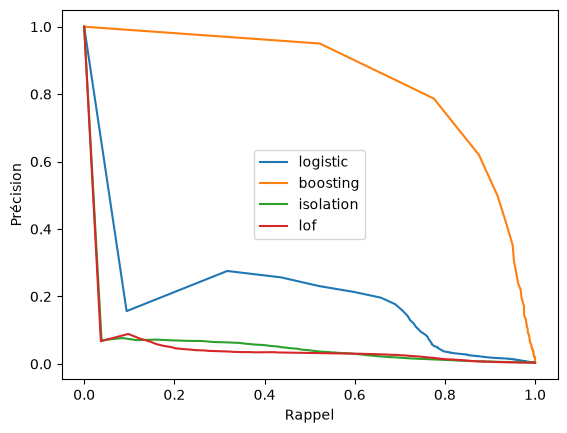

In [8]:
columns=['average_precision','roc_auc','precision_at_k','recall_at_k','f2','mcc','cost']
display(pd.DataFrame(results['test']).T[columns])
import matplotlib.pyplot as plt
for name,m in results['test'].items():
    plt.plot(m['pr_curve']['recall'],m['pr_curve']['precision'],label=name)
plt.xlabel('Rappel'); plt.ylabel('Précision'); plt.legend(); plt.show()

## 8. Seuil optimisé en validation
Coût = somme montants frauduleux × (1 − efficacité × alerte) + coût d’analyse × alertes. Seuil exact parmi les scores distincts, sous capacité par jour de validation. Choix du modèle par coût validation, AP pour départager. Hyperparamètres conservateurs fixés ; pas de recherche exhaustive.

In [9]:
winner=results['winner']
policy=results['selection'][winner]['selected']['policy']
display(policy)
assert policy['selected_on']=='validation'

{'threshold': 0.8826259267588804,
 'cost': 31405.929999998185,
 'alerts': 3222,
 'capacity': 50,
 'investigation': 5.0,
 'effectiveness': 1.0,
 'selected_on': 'validation'}

## 9. Test indépendant
Le seuil est gelé avant scoring du test. @k classe a posteriori k dossiers par jour ; une telle sélection exige de voir le jour entier. Le seuil fixe peut dépasser la capacité sous dérive. L’extrait de 5 000 lignes est une démonstration, pas l’évaluation complète.

In [10]:
test=results['test'][winner]
display({k:v for k,v in test.items() if k!='pr_curve'})
print('Économie face à aucune alerte (USD) :',test['no_alert_cost']-test['cost'])

{'average_precision': 0.8600690596801481,
 'roc_auc': 0.9977174074507773,
 'precision_at_k': 0.202015503875969,
 'recall_at_k': 0.9659006671608599,
 'k': 6450,
 'precision': 0.47256905032160423,
 'recall': 0.9258710155670867,
 'f2': 0.7768379151635776,
 'mcc': 0.6599262637064942,
 'confusion': [[367736, 1394], [100, 1249]],
 'alerts': 2643,
 'peak_alerts_per_day': 47,
 'capacity_exceeded': False,
 'cost': 24534.66,
 'no_alert_cost': 733911.72}

Économie face à aucune alerte (USD) : 709377.0599999999


## 10. SHAP et interprétation critique
Contributions réelles en log-odds de fraude. La somme des modalités one-hot de catégorie conserve l’additivité. Le fond de la logistique provient du train ; TreeSHAP du boosting suit les chemins appris sur train. Associations, sans causalité ni certitude forensique. Les catégories et valeurs manquantes sont grises, sans ordre fictif.

C:\Users\User\Projects\FraudInsight-XAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\User\Projects\FraudInsight-XAI\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


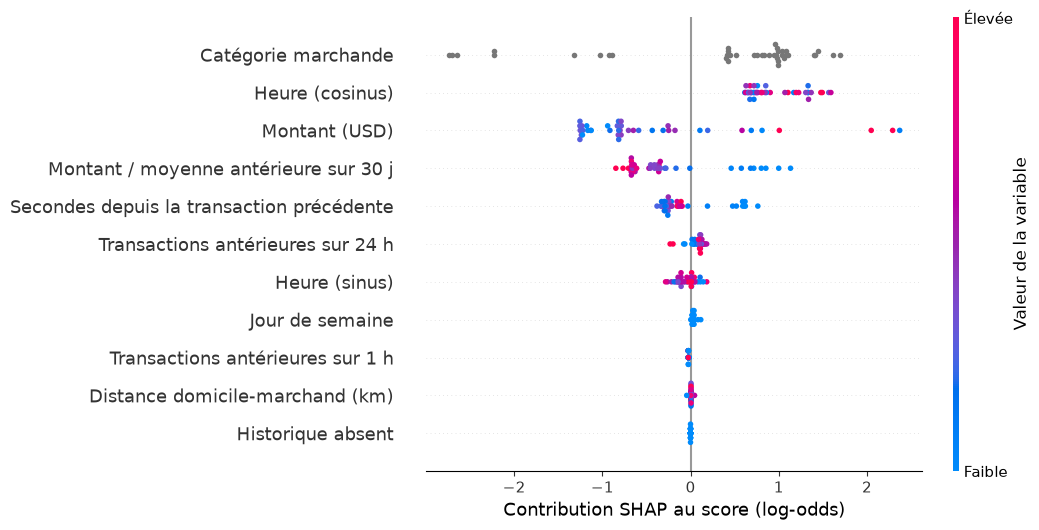

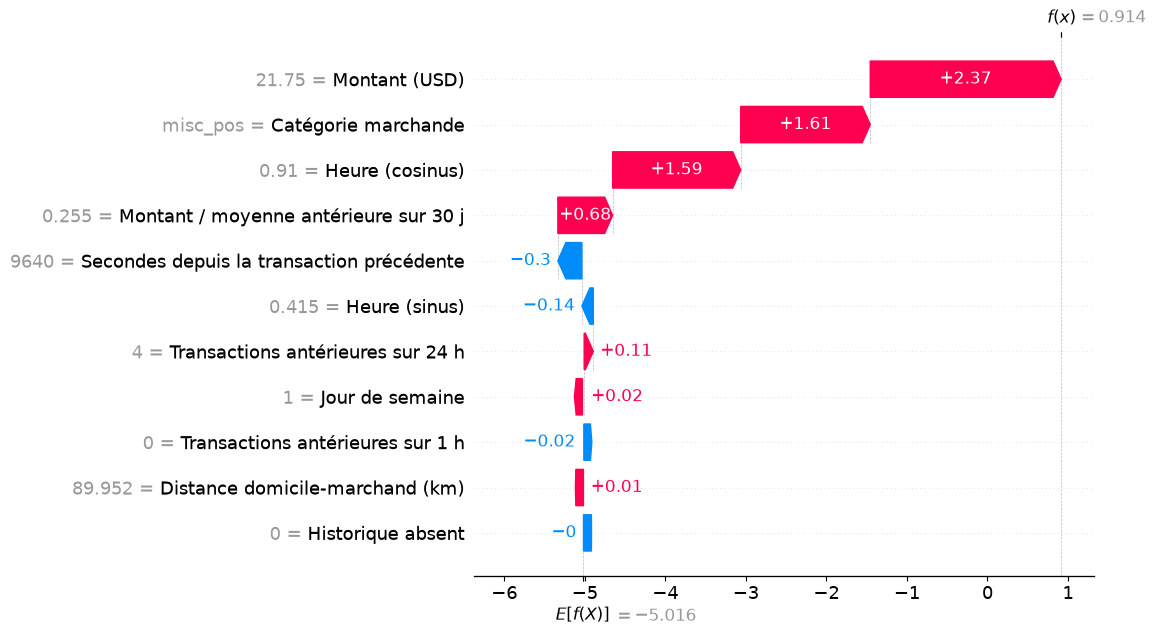

In [11]:
from src.registry import load_bundle
from src.explain import explain
from src.plots import shap_figure
name='boosting'
e=explain(load_bundle(name),demo[FEATURES].iloc[:40])
v=np.array(e['values']); base=np.array(e['base_values'])
assert np.allclose(base+v.sum(axis=1),e['raw_output'],atol=1e-5)
shap_figure(e); plt.show()
row=int(np.argmax(demo['score_'+name].iloc[:40]))
shap_figure(e,'waterfall',row); plt.show()